# Task 5 — Feature Engineering & Feature Selection
### UniMatch AI — 10-Task Computational Intelligence Pipeline

**Input:** Clean datasets from Task 4 (`university_master_clean.csv`, `graduate_admission_clean.csv`)

**Steps:** Derived feature generation (Fit Score, Affordability Index, Admit-Chance Index, Rank-Tier) → Encoding categorical attributes → Correlation analysis → Feature importance ranking → Feature selection

**Deliverables:** Feature Engineering Report, Feature Matrix, Correlation Matrix, Feature Importance Report, Selected Features

> **Note on data:** the merged applicant-university dataset (`university_master_clean.csv`) does not contain a tuition/fee or country column, so a literal "Affordability Index" and country-based encoding can't be computed from it as-is. This notebook builds the closest honest equivalents from what's actually in the data (using `avg_rank_all3`/`total_students`/`intl_students_pct` as cost-adjacent proxies) and says so explicitly in the Feature Engineering Report rather than faking numbers. If you have a fee/country table, drop it in the "optional" cell in Section 1 and it will be joined in automatically.

## 0. Setup

In [1]:
import importlib, subprocess, sys

# Only install what's missing instead of uninstalling/force-reinstalling everything.
# The previous force-reinstall of numpy/pandas/scikit-learn routinely crashed the
# Colab runtime (binary incompatibility) and required a manual restart, which broke
# every cell below it. Installing only if a package is missing is safe and fast.
required = ['pandas', 'numpy', 'scipy', 'sklearn', 'matplotlib', 'seaborn']
pip_names = {'sklearn': 'scikit-learn'}
for pkg in required:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_names.get(pkg, pkg)])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.model_selection import train_test_split, GroupShuffleSplit
import os, re, json

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# Local run (from the repository's notebooks/ folder): write straight into ../outputs/task5_output and
# ../reports. In Colab, fall back to ./task5_outputs as before.
LOCAL_REPO = os.path.isdir('../outputs')
out_dir = '../outputs/task5_output' if LOCAL_REPO else './task5_outputs'
report_dir = '../reports' if os.path.isdir('../reports') else out_dir
os.makedirs(out_dir, exist_ok=True)


## 1. Load Task 4 outputs

Upload `university_master_clean.csv` and `graduate_admission_clean.csv` to the Colab file browser (left sidebar) before running, or mount Drive and adjust the paths.

In [2]:
import os
DRIVE_DIR = '/content/drive/MyDrive/UniMatch'
# Task 4 writes its CSVs to ./outputs - if Task 4 ran in this same Colab session they are found there,
# so nothing has to be uploaded (browser uploads of large CSVs can get cut off part-way).
# A local run from the repository's notebooks/ folder reads ../outputs/task4_output.
SEARCH_DIRS = ['.', './outputs', '../outputs/task4_output', DRIVE_DIR, f'{DRIVE_DIR}/outputs']

def find_file(*names):
    for name in names:
        for d in SEARCH_DIRS:
            p = os.path.join(d, name)
            if os.path.exists(p):
                return p
    try:
        from google.colab import files
        print(f"'{names[0]}' not found - please upload it (or run Task 4 in this session first):")
        files.upload()
        return names[0]
    except ModuleNotFoundError:
        raise FileNotFoundError(f"Could not find any of {names} in {SEARCH_DIRS}.")

uni_path = find_file('university_master_clean.csv', 'university_master_clean (1).csv')
grad_path = find_file('graduate_admission_clean.csv', 'graduate_admission_clean (1).csv')   # unscaled: scaling happens in Task 6 on the train split

uni_df = pd.read_csv(uni_path, low_memory=False)
grad_df = pd.read_csv(grad_path)

# Integrity check: Task 4 leaves no missing values in 'admit'. Missing values here mean the CSV was
# cut off during upload -> stop instead of silently training on part of the data.
n_bad = int(uni_df['admit'].isna().sum())
if n_bad:
    raise ValueError(f"{n_bad} row(s) of university_master_clean.csv have no 'admit' value - the file is truncated "
                     f"(only {len(uni_df)} rows loaded; the full file has ~53,500). Re-run Task 4 in this session "
                     "or copy the file via Google Drive instead of uploading it.")

print('university_master_clean:', uni_df.shape, 'from', uni_path)
print('graduate_admission_clean:', grad_df.shape, 'from', grad_path)
uni_df.head()


university_master_clean: (53527, 54) from ../outputs/task4_output/university_master_clean.csv
graduate_admission_clean: (500, 9) from ../outputs/task4_output/graduate_admission_clean.csv


,username,major,researchexp,industryexp,specialization,toeflscore,program,department,internexp,grev,greq,userprofilelink,journalpubs,grea,toppercgpa,termandyear,confpubs,ugcollege,cgpa,cgpascale,univname,admit,univ_key,university,country,region,university_type,qs_rank_2026,the_rank_2026,arwu_rank_2025,qs_score,the_score,arwu_score,qs_academic_rep,qs_employer_rep,qs_faculty_student,qs_citations,qs_intl_faculty,qs_intl_students,the_teaching,the_research_env,the_research_quality,the_industry,the_intl_outlook,founded,total_students,intl_students_pct,nobel_laureates,fields_medalists,ranked_in_all_3,avg_rank_all3,university_age_2026,data_sources,is_ranked
0,143saf,Systems and Control,0,18,Robotics,112.0,MS,Instrumentation & Control,5.0,160.0,167.0,http://www.edulix.com/unisearch/user.php?uid=2...,0.0,4.5,8.9,Fall - 2015,0.0,Dharamsinh Desai University,8.50,10.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,7790ashish,Manufacturing Engineering,0,0,VLSI,106.0,MS,0,0.0,153.0,166.0,http://www.edulix.com/unisearch/user.php?uid=1...,0.0,3.5,0.0,Fall - 2013,0.0,MU,58.00,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,AB25,(MIS / MSIM / MSIS / MSIT),0,66,VLSI,94.0,MS,Computer Engineering,0.0,146.0,157.0,http://www.edulix.com/unisearch/user.php?uid=2...,0.0,3.0,81.0,Fall - 2015,0.0,IET DAVV,78.28,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,abhijitg,Computer Science,0,0,VLSI,106.0,MS,0,0.0,153.0,166.0,http://www.edulix.com/unisearch/user.php?uid=1...,0.0,3.5,0.0,Fall - 2013,0.0,MU,58.00,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,abhijitgang,MIS,0,0,VLSI,81.0,MS,computer,0.0,145.0,168.0,http://www.edulix.com/unisearch/user.php?uid=1...,0.0,2.5,70.0,Fall - 2011,0.0,Pune University,57.00,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [3]:
# OPTIONAL: join an external country / tuition-fee lookup table here if you have one,
# e.g. a CSV with columns [univname, country, avg_tuition_usd].
# fees_df = pd.read_csv('university_fees_country.csv')
# uni_df = uni_df.merge(fees_df, on='univname', how='left')
uni_df.columns.tolist()


['username',
 'major',
 'researchexp',
 'industryexp',
 'specialization',
 'toeflscore',
 'program',
 'department',
 'internexp',
 'grev',
 'greq',
 'userprofilelink',
 'journalpubs',
 'grea',
 'toppercgpa',
 'termandyear',
 'confpubs',
 'ugcollege',
 'cgpa',
 'cgpascale',
 'univname',
 'admit',
 'univ_key',
 'university',
 'country',
 'region',
 'university_type',
 'qs_rank_2026',
 'the_rank_2026',
 'arwu_rank_2025',
 'qs_score',
 'the_score',
 'arwu_score',
 'qs_academic_rep',
 'qs_employer_rep',
 'qs_faculty_student',
 'qs_citations',
 'qs_intl_faculty',
 'qs_intl_students',
 'the_teaching',
 'the_research_env',
 'the_research_quality',
 'the_industry',
 'the_intl_outlook',
 'founded',
 'total_students',
 'intl_students_pct',
 'nobel_laureates',
 'fields_medalists',
 'ranked_in_all_3',
 'avg_rank_all3',
 'university_age_2026',
 'data_sources',
 'is_ranked']

## 2. Derived Feature Generation

Dataset A (`uni_df`) is applicant-level, joined to the university the applicant applied to, with `admit` (0/1) as the outcome. We engineer:

- **Rank-Tier** — Tier 1 (rank ≤ 10), Tier 2 (11-25), Tier 3 (26-50), Tier 4 (> 50) from `avg_rank_all3`; rows whose university is not in the rankings file get **Unranked** (uses the `is_ranked` flag from Task 4)
- **Admit-Chance Index** — a 0–1 composite of the applicant's academic strength (CGPA %, GRE-Q, GRE-V, TOEFL, research/industry exp), built without looking at the outcome
- **Train / validation / test split (by applicant)** — each applicant applied to several universities, so the split assigns whole applicants (not rows) to train / val / test (64 / 16 / 20). The split is saved and reused by Tasks 6-8
- **Fit Score** — how close the applicant's profile is to the typical *admitted* profile at that university. Because it uses the `admit` label, the admitted-cohort statistics are computed from the **training split only**, so no validation/test outcomes leak into the feature
- **Affordability Index (proxy)** — no fee/cost column exists, so a *resource-availability proxy* from `total_students`, `intl_students_pct` and rank is built for ranked universities only, and clearly labelled as a proxy

Dataset B (`grad_df`) comes with `chance_of_admit` as a continuous target. `university_rating` (1-5) is already an ordinal tier, so it is used directly; we add an **Admit-Chance Index** composite as a cross-check (reference column only, not a model feature), and a stratified 60 / 20 / 20 train / val / test split.


In [4]:
# ---- 2.1 Rank-Tier (Dataset A) ----
# Tiers use FIXED rank bands, one tier per university. (A quantile split over applicant ROWS
# would split applicants of the SAME university into different tiers just by row order.)
# Rows whose university is not in the rankings file (is_ranked == 0) get 'Unranked'.
rank_col = 'avg_rank_all3' if uni_df['avg_rank_all3'].notna().sum() > 0 else 'qs_rank_2026'
TIER_LABELS = ['Tier 1', 'Tier 2', 'Tier 3', 'Tier 4']

tier = pd.cut(uni_df[rank_col], bins=[0, 10, 25, 50, np.inf], labels=TIER_LABELS).astype(object)
tier[uni_df['is_ranked'] != 1] = 'Unranked'
uni_df['rank_tier'] = pd.Categorical(tier, categories=TIER_LABELS + ['Unranked'])

print(f"Rows with a real rank: {int(uni_df['is_ranked'].sum())} / {len(uni_df)} "
      f"({uni_df['is_ranked'].mean()*100:.1f}%)")
uni_df['rank_tier'].value_counts()


Rows with a real rank: 5695 / 53527 (10.6%)


rank_tier
Unranked    47832
Tier 2       2711
Tier 3       2406
Tier 1        578
Tier 4          0
Name: count, dtype: int64

In [5]:
# ---- 2.2 Admit-Chance Index (Dataset A) — applicant academic strength, 0-1 ----
strength_cols = ['cgpa', 'cgpascale', 'greq', 'grev', 'grea', 'toeflscore', 'researchexp', 'industryexp']

# Normalise cgpa onto a common 0-100 scale using cgpascale where available
uni_df['cgpa_pct'] = np.where(uni_df['cgpascale'] > 0, (uni_df['cgpa'] / uni_df['cgpascale']) * 100, np.nan)
uni_df['cgpa_pct'] = uni_df['cgpa_pct'].clip(0, 100)

def minmax(s):
    s = s.astype(float)
    lo, hi = s.quantile(0.01), s.quantile(0.99)  # robust to outliers
    return ((s.clip(lo, hi) - lo) / (hi - lo + 1e-9)).fillna(0)

admit_index_components = pd.DataFrame({
    'cgpa_n':        minmax(uni_df['cgpa_pct']),
    'greq_n':        minmax(uni_df['greq']),
    'grev_n':        minmax(uni_df['grev']),
    'toefl_n':       minmax(uni_df['toeflscore']),
    'researchexp_n': minmax(uni_df['researchexp']),
    'industryexp_n': minmax(uni_df['industryexp']),
})
weights = {'cgpa_n': 0.30, 'greq_n': 0.20, 'grev_n': 0.15, 'toefl_n': 0.15, 'researchexp_n': 0.12, 'industryexp_n': 0.08}
uni_df['admit_chance_index'] = sum(admit_index_components[c] * w for c, w in weights.items())
uni_df[['cgpa_pct', 'greq', 'grev', 'toeflscore', 'admit_chance_index']].describe()


,cgpa_pct,greq,grev,toeflscore,admit_chance_index
count,53527.000000,53527.000000,53527.000000,53527.000000,53527.000000
mean,75.290869,164.911876,153.251387,105.360267,0.516235
std,12.262545,4.626928,5.929636,7.307899,0.111303
min,1.000000,136.000000,132.000000,57.000000,0.000000
25%,68.085000,162.000000,149.000000,101.000000,0.441261
50%,76.000000,166.000000,153.000000,106.000000,0.522273
75%,83.500000,169.000000,157.000000,110.000000,0.596270
max,100.000000,170.000000,170.000000,120.000000,0.917662


In [6]:
# ---- 2.3 Train / validation / test split, then Fit Score (Dataset A) ----
# Split BY APPLICANT: each applicant (`username`) applied to several universities. A row-level random
# split put 91% of test rows' applicants into the training set as well, so the models were partly
# tested on people they had already seen. Here all rows of one applicant land in the same part:
# 20% of applicants -> test, 20% of the remaining applicants -> validation (used by Tasks 6-7 to choose
# models; the test set is only used for the final numbers). The split is saved as a `split` column
# and reused unchanged by Tasks 6-8.
#
# FIX (target leakage): fit_score is built from the `admit` label, so the admitted-cohort mean/std
# must come from TRAINING rows only. We compute each university's admitted-cohort stats from train
# rows, and apply the SAME stats to every row of that university (train, validation and test).
# The earlier leave-one-out version gave admitted rows slightly different statistics from
# rejected rows at the same university - the model could read `admit` straight off those
# columns, which is why Task 6 reached ROC-AUC = 1.0.
fit_feature_cols = ['cgpa_pct', 'greq', 'grev', 'toeflscore']

uni_df['admit'] = uni_df['admit'].astype(int)   # no NaNs here - checked when the file was loaded

applicant = uni_df['username'].astype(str)
dev_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
                         .split(uni_df, groups=applicant))
train_pos, val_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
                          .split(dev_idx, groups=applicant.iloc[dev_idx]))
split = np.full(len(uni_df), 'test', dtype=object)
split[dev_idx[train_pos]] = 'train'
split[dev_idx[val_pos]] = 'val'
uni_df['split'] = split

parts = {s: set(applicant[uni_df['split'] == s]) for s in ('train', 'val', 'test')}
assert not (parts['train'] & parts['val'] or parts['train'] & parts['test'] or parts['val'] & parts['test']), \
    'an applicant appears in more than one split'

admitted_train = uni_df[(uni_df['split'] == 'train') & (uni_df['admit'] == 1)]
cohort_mean = admitted_train.groupby('univname')[fit_feature_cols].mean()
cohort_std = admitted_train.groupby('univname')[fit_feature_cols].std()

z_dists = []
for c in fit_feature_cols:
    mu = uni_df['univname'].map(cohort_mean[c])
    sd = uni_df['univname'].map(cohort_std[c]).replace(0, np.nan).fillna(1)
    z_dists.append(((uni_df[c] - mu) / sd).abs())
uni_df['profile_distance'] = pd.concat(z_dists, axis=1).mean(axis=1)
train_median = uni_df.loc[uni_df['split'] == 'train', 'profile_distance'].median()
uni_df['profile_distance'] = uni_df['profile_distance'].fillna(train_median)
uni_df['fit_score'] = 1 / (1 + uni_df['profile_distance'])  # bounded (0,1], higher = closer fit

print(uni_df['split'].value_counts())
print('applicants per split:', {s: len(a) for s, a in parts.items()})
uni_df[['univname', 'profile_distance', 'fit_score']].sample(5, random_state=RANDOM_STATE)


split
train    34207
test     10741
val       8579
Name: count, dtype: int64
applicants per split: {'train': 9470, 'val': 2368, 'test': 2960}


,univname,profile_distance,fit_score
16759,University of Illinois Urbana-Champaign,0.589194,0.629250
6939,University of Texas Austin,0.903871,0.525246
50858,Arizona State University,1.133831,0.468641
27811,Texas A and M University College Station,0.631628,0.612885
47287,Cornell University,1.065720,0.484093


In [7]:
# ---- 2.4 Affordability Index (PROXY — see note in Section 1) ----
# No tuition/fee/country column is present. We approximate "affordability/access" from institution
# scale, international share and rank - NOT a real cost measure. It can only be computed for
# universities that exist in the rankings file, so it is NaN for unranked rows (not faked).
# Min-max scaling is done over the 57 ranked universities, not over applicant rows.
def minmax_ref(s, ref):
    lo, hi = ref.min(), ref.max()
    return (s - lo) / (hi - lo) if hi > lo else s * 0 + 0.5

ref = uni_df[uni_df['is_ranked'] == 1].drop_duplicates('univname')
uni_df['affordability_index_proxy'] = (
    0.4 * minmax_ref(uni_df['total_students'], ref['total_students']) +
    0.3 * minmax_ref(uni_df['intl_students_pct'], ref['intl_students_pct']) +
    0.3 * (1 - minmax_ref(uni_df[rank_col], ref[rank_col]))   # better (lower) rank -> typically higher cost
)
uni_df.loc[uni_df['is_ranked'] != 1, 'affordability_index_proxy'] = np.nan
uni_df.loc[uni_df['is_ranked'] == 1, ['univname', rank_col, 'affordability_index_proxy']].drop_duplicates('univname')


,univname,avg_rank_all3,affordability_index_proxy
10851,University of Pennsylvania,13.0,0.459920
14129,University of Michigan Ann Arbor,22.0,0.588636
24908,University of California Los Angeles,31.0,0.493336
34937,Stanford University,3.3,0.508598
36865,Princeton University,8.3,0.403529
43366,New York University,32.5,0.588314
44360,Massachusetts Institute of Technology,2.0,0.552618
44460,Johns Hopkins University,22.5,0.489226
44647,Harvard University,3.7,0.547725
47063,Cornell University,15.5,0.510747


In [8]:
# ---- 2.5 Dataset B (grad_df) equivalents, for cross-check against its real chance_of_admit label ----
grad_strength_cols = ['gre_score', 'toefl_score', 'cgpa', 'sop', 'lor', 'research']
grad_components = pd.DataFrame({c: minmax(grad_df[c]) for c in grad_strength_cols})
grad_weights = {'gre_score': 0.25, 'toefl_score': 0.15, 'cgpa': 0.30, 'sop': 0.10, 'lor': 0.10, 'research': 0.10}
grad_df['admit_chance_index'] = sum(grad_components[c] * w for c, w in grad_weights.items())

# This composite is kept as a reference column only - it is NOT a model feature (see Section 5).
# `university_rating` (1-5, 5 = best) is already an ordinal rank tier, so it is used directly.
# (The earlier quantile split of it broke ties by row order, putting students with the SAME
# rating into different tiers, and labelled the lowest ratings 'Tier 1'.)
# Train / validation / test split for Dataset B (60 / 20 / 20), stratified on the Task 6 label
# (chance_of_admit >= 0.7). The test rows are the same 100 rows as the earlier Task 6 split.
GRAD_THRESHOLD = 0.7
grad_label = (grad_df['chance_of_admit'] >= GRAD_THRESHOLD).astype(int)
g_dev, g_test = train_test_split(grad_df.index, test_size=0.2, random_state=RANDOM_STATE, stratify=grad_label)
g_train, g_val = train_test_split(g_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=grad_label[g_dev])
grad_df['split'] = 'test'
grad_df.loc[g_train, 'split'] = 'train'
grad_df.loc[g_val, 'split'] = 'val'
print(grad_df['split'].value_counts())
grad_df[['admit_chance_index', 'chance_of_admit', 'university_rating', 'split']].head()


split
train    300
test     100
val      100
Name: count, dtype: int64


,admit_chance_index,chance_of_admit,university_rating,split
0,0.924436,0.92,4,train
1,0.681655,0.76,4,test
2,0.462929,0.72,3,train
3,0.595281,0.80,3,train
4,0.331333,0.65,2,train


## 3. Encoding Categorical Attributes

Dataset A: `program` (degree level), `department`, `specialization`, `univname`, `rank_tier` (derived above). Dataset B needs no encoding (`university_rating` is already numeric/ordinal).
There is no explicit `country` column in the source data — see the note in Section 1.

- `program`, `rank_tier`, `univname` (54 universities) → one-hot encoding
- `department`, `specialization` (thousands of free-text levels) → one-hot for levels with ≥ 200 training rows (rarer levels share an all-zero "other" encoding) + frequency encoding
- No label (integer) encoding: alphabetical codes have no order, so Logistic Regression / SVM / the DNN cannot use them
- Vocabularies and frequencies come from **training rows only** and are saved to `category_encodings.json`

In [9]:
# One-hot: program (4 levels), rank_tier and univname (54 universities).
# department / specialization have ~1,500 and ~3,600 free-text levels, so each gets one-hot columns for
# the levels with at least MIN_LEVEL_ROWS training rows (every other level -> all zeros) plus a
# frequency encoding.
# The earlier version fed LabelEncoder codes (alphabetical integers) to the models as numbers. Tree
# models can split on such codes, but for Logistic Regression, SVM and the DNN "university #23 >
# university #7" is meaningless - which is a large part of why they trailed XGBoost.
# Vocabularies and frequencies come from TRAINING rows only and are saved to category_encodings.json,
# so the application builds exactly the same columns for a new applicant.
MIN_LEVEL_ROWS = 200
train_rows = uni_df['split'] == 'train'

def column_name(prefix, level, taken):
    name = prefix + '_' + (re.sub(r'[^0-9A-Za-z]+', '_', str(level)).strip('_') or 'blank')
    while name in taken:
        name += '_'
    return name

encoded_uni = uni_df.copy()
category_encodings = {'min_level_rows': MIN_LEVEL_ROWS}
onehot_groups = {}
for col, prefix, min_rows in [('program', 'program', 1), ('univname', 'univ', 1),
                              ('department', 'dept', MIN_LEVEL_ROWS), ('specialization', 'spec', MIN_LEVEL_ROWS)]:
    values = uni_df[col].astype(str)
    counts = values[train_rows].value_counts()
    mapping = {}
    for level in sorted(counts[counts >= min_rows].index):
        mapping[level] = column_name(prefix, level, set(mapping.values()) | set(encoded_uni.columns))
        encoded_uni[mapping[level]] = (values == level).astype(int)
    category_encodings[col] = {'columns': mapping}
    onehot_groups[col] = list(mapping.values())

for col in ['department', 'specialization']:
    freq = uni_df.loc[train_rows, col].astype(str).value_counts(normalize=True)
    encoded_uni[f'{col}_freq'] = uni_df[col].astype(str).map(freq).fillna(0.0)
    category_encodings[col]['frequency'] = freq.to_dict()

encoded_uni = pd.get_dummies(encoded_uni, columns=['rank_tier'], prefix='rank_tier', dtype=int)

print('New shape after encoding:', encoded_uni.shape)
print({col: len(cols) for col, cols in onehot_groups.items()}, 'one-hot columns per attribute')


New shape after encoding: (53527, 161)
{'program': 4, 'univname': 54, 'department': 27, 'specialization': 9} one-hot columns per attribute


In [10]:
# grad_df: all columns already numeric (research is 0/1, university_rating is ordinal 1-5)
encoded_grad = grad_df.copy()
encoded_grad.head()


,serial_no,gre_score,toefl_score,university_rating,sop,lor,cgpa,research,chance_of_admit,admit_chance_index,split
0,1,337,118,4,4.5,4.5,9.65,1,0.92,0.924436,train
1,2,324,107,4,4.0,4.5,8.87,1,0.76,0.681655,test
2,3,316,104,3,3.0,3.5,8.00,1,0.72,0.462929,train
3,4,322,110,3,3.5,2.5,8.67,1,0.80,0.595281,train
4,5,314,103,2,2.0,3.0,8.21,0,0.65,0.331333,train


## 4. Correlation Analysis

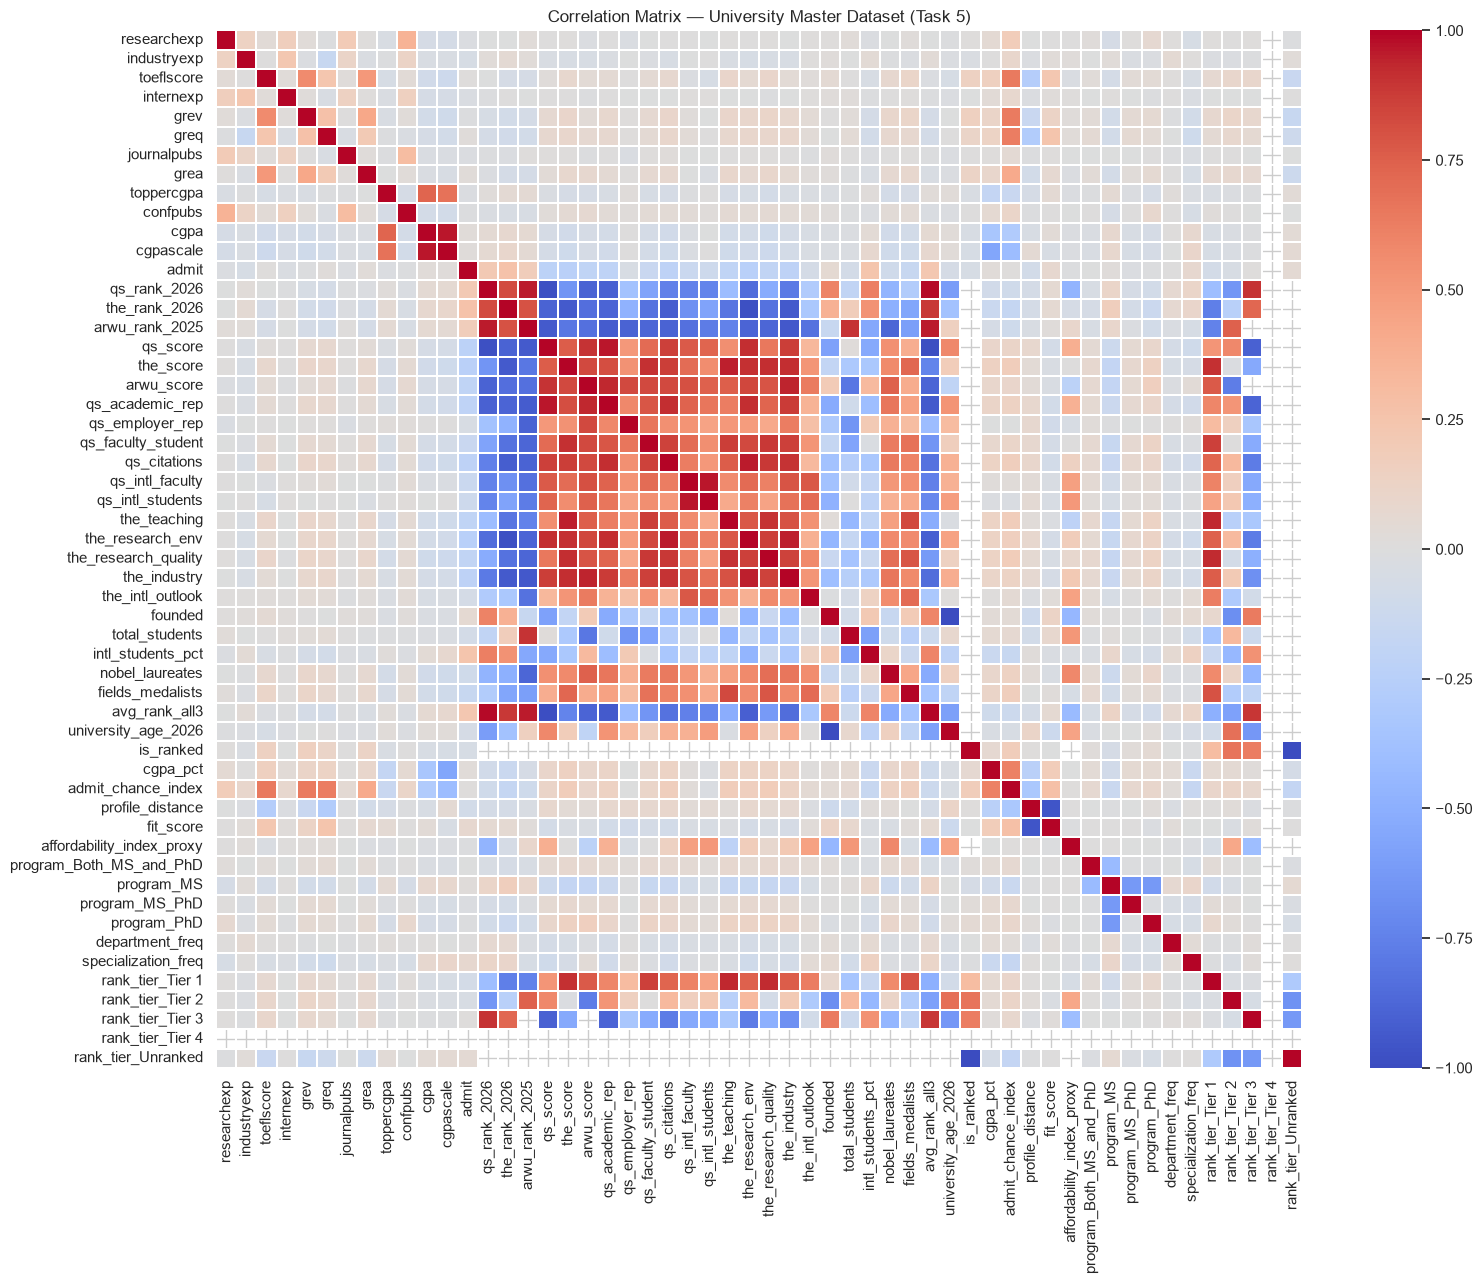

In [11]:
# The one-hot columns for univname / department / specialization are left out of the correlation
# analysis (≈100 sparse indicator columns would swamp the heatmap); they are not subject to the
# correlation filter in Section 6 either.
id_onehot_cols = onehot_groups['univname'] + onehot_groups['department'] + onehot_groups['specialization']
numeric_uni = encoded_uni.select_dtypes(include=[np.number]).drop(columns=['serial_no'], errors='ignore')
corr_matrix_uni = numeric_uni.drop(columns=id_onehot_cols).corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix_uni, cmap='coolwarm', center=0, linewidths=0.3,
            xticklabels=True, yticklabels=True)
plt.title('Correlation Matrix — University Master Dataset (Task 5)')
plt.tight_layout()
plt.savefig(f'{out_dir}/correlation_matrix_university.png', dpi=150)
plt.show()


In [12]:
# Only columns with no missing values are compared. Ranking columns exist for ~11% of rows,
# so their correlation would describe the 13 ranked universities only, not the whole dataset.
complete_cols = [c for c in corr_matrix_uni.columns if numeric_uni[c].notna().all()]
corr_with_admit = corr_matrix_uni.loc[complete_cols, 'admit'].drop('admit').sort_values(key=abs, ascending=False)
print('Top correlations with admit (target):')
corr_with_admit.head(15)


Top correlations with admit (target):


profile_distance      -0.080499
specialization_freq    0.075758
fit_score              0.075714
rank_tier_Tier 1      -0.072553
industryexp           -0.049746
rank_tier_Unranked     0.047140
is_ranked             -0.047140
rank_tier_Tier 2      -0.043343
internexp             -0.028380
grea                   0.026113
cgpa_pct               0.025090
cgpa                   0.024156
journalpubs           -0.022850
cgpascale              0.021784
program_MS             0.019955
Name: admit, dtype: float64

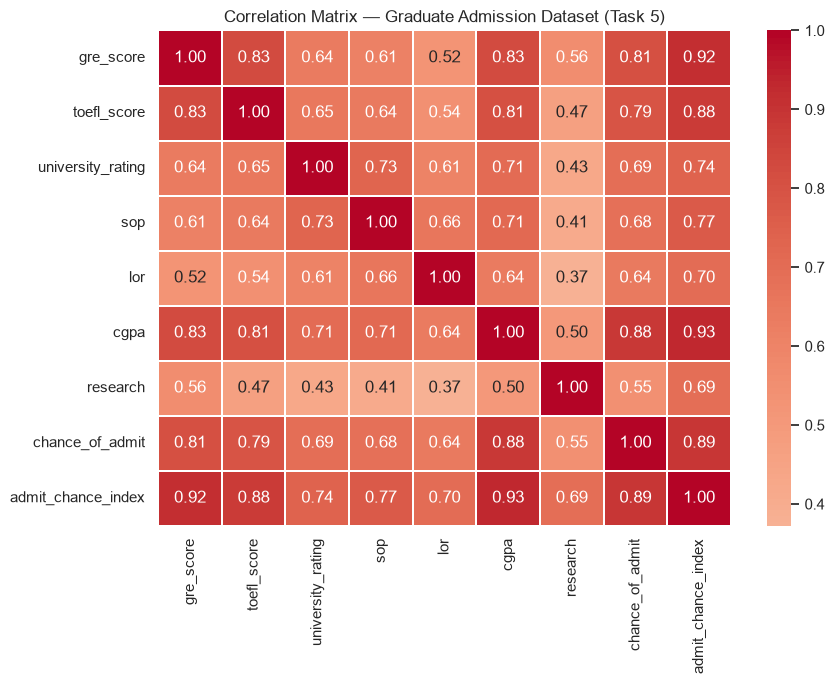

In [13]:
numeric_grad = encoded_grad.select_dtypes(include=[np.number]).drop(columns=['serial_no'], errors='ignore')
corr_matrix_grad = numeric_grad.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix_grad, cmap='coolwarm', center=0, annot=True, fmt='.2f', linewidths=0.3)
plt.title('Correlation Matrix — Graduate Admission Dataset (Task 5)')
plt.tight_layout()
plt.savefig(f'{out_dir}/correlation_matrix_graduate.png', dpi=150)
plt.show()


In [14]:
corr_matrix_grad['chance_of_admit'].drop('chance_of_admit').sort_values(key=abs, ascending=False)


admit_chance_index    0.893777
cgpa                  0.882413
gre_score             0.810351
toefl_score           0.792228
university_rating     0.690132
sop                   0.684137
lor                   0.644737
research              0.545871
Name: chance_of_admit, dtype: float64

## 5. Feature Importance Ranking

Using a Random Forest against each dataset's target:
- Dataset A → `RandomForestClassifier` predicting `admit`
- Dataset B → `RandomForestRegressor` predicting `chance_of_admit`

Mutual information is computed alongside as a non-linear, model-free cross-check.

In [15]:
# ---- Dataset A: RandomForestClassifier on admit ----
# Excluded from the feature set:
#  - identifiers / free text (the categorical attributes enter through their one-hot / frequency columns)
#  - raw ranking columns: they exist for only ~11% of rows (NaN = not ranked)
#  - is_ranked / rank_tier_*: fixed per university, so the univ_* one-hot columns already carry them
#  - affordability_index_proxy: ranked rows only - kept in the data for Tasks 3/9
#  - raw cgpa / cgpascale: different grading scales, replaced by the normalised `cgpa_pct`
ranking_raw_cols = ['qs_rank_2026', 'the_rank_2026', 'arwu_rank_2025', 'qs_score', 'the_score', 'arwu_score',
                    'qs_academic_rep', 'qs_employer_rep', 'qs_faculty_student', 'qs_citations', 'qs_intl_faculty',
                    'qs_intl_students', 'the_teaching', 'the_research_env', 'the_research_quality', 'the_industry',
                    'the_intl_outlook', 'founded', 'total_students', 'intl_students_pct', 'nobel_laureates',
                    'fields_medalists', 'avg_rank_all3', 'university_age_2026', 'ranked_in_all_3']
drop_cols_a = ['admit', 'username', 'userprofilelink', 'termandyear', 'ugcollege',
               'department', 'specialization', 'univname', 'journalpubs', 'confpubs',
               'cgpa', 'cgpascale', 'affordability_index_proxy'] + ranking_raw_cols
university_level_cols = ['is_ranked'] + [c for c in numeric_uni.columns if c.startswith('rank_tier_')]
onehot_cols_a = onehot_groups['program'] + id_onehot_cols
numeric_candidates_a = [c for c in numeric_uni.columns
                        if c not in drop_cols_a + university_level_cols + onehot_cols_a]
feature_cols_a = numeric_candidates_a + onehot_cols_a

train_mask = uni_df['split'] == 'train'
train_medians = numeric_uni.loc[train_mask, feature_cols_a].median()
X_a = numeric_uni[feature_cols_a].fillna(train_medians)
y_a = uni_df['admit']

# Importance is measured on TRAIN rows only, so feature selection never sees validation or test rows
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
rf_clf.fit(X_a[train_mask], y_a[train_mask])

importance_a = pd.Series(rf_clf.feature_importances_, index=feature_cols_a).sort_values(ascending=False)

mi_a = pd.Series(
    mutual_info_classif(X_a[train_mask], y_a[train_mask], random_state=RANDOM_STATE),
    index=feature_cols_a
).sort_values(ascending=False)

feature_importance_report_a = pd.DataFrame({
    'rf_importance': importance_a,
    'mutual_info': mi_a.reindex(importance_a.index)
}).sort_values('rf_importance', ascending=False)

print('Total RF importance per one-hot group:',
      {col: round(importance_a[cols].sum(), 3) for col, cols in onehot_groups.items()})
feature_importance_report_a.head(20)


Total RF importance per one-hot group: {'program': np.float64(0.007), 'univname': np.float64(0.398), 'department': np.float64(0.06), 'specialization': np.float64(0.025)}


,rf_importance,mutual_info
cgpa_pct,0.084121,0.012834
univ_University_of_Texas_Dallas,0.064234,0.010410
fit_score,0.064023,0.006583
admit_chance_index,0.060715,0.050063
profile_distance,0.056419,0.006707
univ_University_of_Texas_Austin,0.047865,0.004195
specialization_freq,0.039741,0.010740
toeflscore,0.037247,0.003133
grev,0.034357,0.003256
greq,0.032795,0.000000


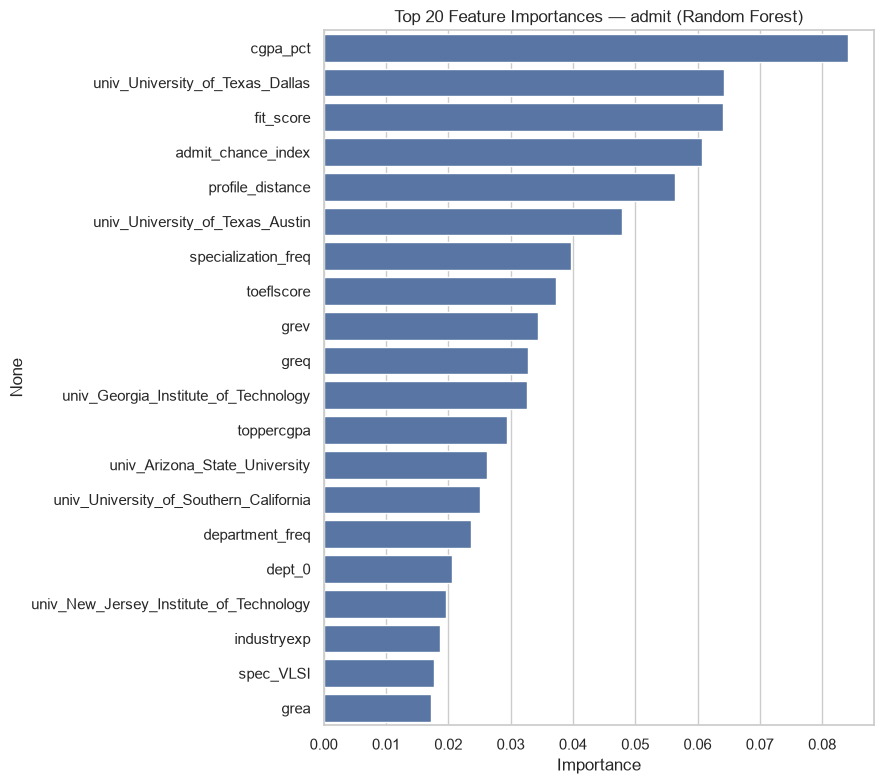

In [16]:
plt.figure(figsize=(9, 8))
top_n = 20
sns.barplot(x=importance_a.head(top_n).values, y=importance_a.head(top_n).index, color='#4C72B0')
plt.title(f'Top {top_n} Feature Importances — admit (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig(f'{out_dir}/feature_importance_university.png', dpi=150)
plt.show()


In [17]:
# ---- Dataset B: RandomForestRegressor on chance_of_admit ----
# The raw applicant attributes are the candidates. `admit_chance_index` is left out: it is a fixed,
# hand-weighted mix of these same columns. With it in the candidate set, the correlation filter
# below dropped CGPA, GRE, LOR and research (|corr| > 0.90 with the index), so the models could only
# use Task 5's weights instead of learning how much each attribute matters.
feature_cols_b = [c for c in numeric_grad.columns if c not in ('chance_of_admit', 'admit_chance_index')]
grad_train = grad_df['split'] == 'train'
X_b = numeric_grad[feature_cols_b]
y_b = numeric_grad['chance_of_admit']

# Importance measured on TRAIN rows only (the earlier version used all 500 rows, test rows included)
rf_reg = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf_reg.fit(X_b[grad_train], y_b[grad_train])

importance_b = pd.Series(rf_reg.feature_importances_, index=feature_cols_b).sort_values(ascending=False)
mi_b = pd.Series(
    mutual_info_regression(X_b[grad_train], y_b[grad_train], random_state=RANDOM_STATE),
    index=feature_cols_b
).sort_values(ascending=False)

feature_importance_report_b = pd.DataFrame({
    'rf_importance': importance_b,
    'mutual_info': mi_b.reindex(importance_b.index)
}).sort_values('rf_importance', ascending=False)

feature_importance_report_b


,rf_importance,mutual_info
cgpa,0.781379,0.925118
gre_score,0.110277,0.653172
toefl_score,0.041682,0.666918
lor,0.022363,0.282199
sop,0.020786,0.332417
research,0.013033,0.191114
university_rating,0.010479,0.446150


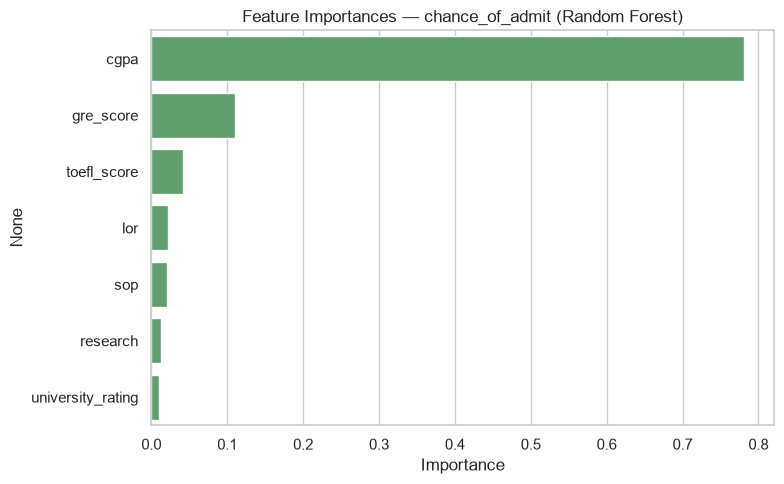

In [18]:
plt.figure(figsize=(8, 5))
sns.barplot(x=importance_b.values, y=importance_b.index, color='#55A868')
plt.title('Feature Importances — chance_of_admit (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig(f'{out_dir}/feature_importance_graduate.png', dpi=150)
plt.show()


## 6. Feature Selection

Rule applied: rank features by RF importance, keep the smallest top-ranked set whose
**cumulative importance covers 95%** of the total (falling back to at least 5 features
if fewer would meet that bar), then drop near-duplicates (pairwise |corr| > 0.90 with an
already-selected, higher-importance feature).

*Why not "importance ≥ mean importance" (the original rule)?* When one engineered feature
(e.g. `admit_chance_index`) dominates because it's a weighted combination of several raw
predictors also present in X, RF importance becomes extremely skewed — the mean sits far
above almost every individual feature, and the old rule collapsed to selecting a single
feature (see the Dataset B result before this fix: 1 of 12 features). The cumulative-importance
rule is far less sensitive to that kind of skew and yields a compact, non-degenerate feature set.


In [19]:
def select_features(importance_series, corr_matrix, corr_threshold=0.90,
                     cum_importance=0.95, min_features=5):
    ranked = importance_series.sort_values(ascending=False)
    total = ranked.sum()
    cum_share = ranked.cumsum() / total if total > 0 else ranked.cumsum()

    # smallest top-N features covering `cum_importance` of total RF importance
    n_for_cum = int((cum_share < cum_importance).sum()) + 1
    n_for_cum = min(max(n_for_cum, min_features), len(ranked))
    candidates = ranked.head(n_for_cum).index.tolist()

    selected = []
    for feat in candidates:
        redundant = False
        for kept in selected:
            if feat in corr_matrix.columns and kept in corr_matrix.columns:
                if abs(corr_matrix.loc[feat, kept]) > corr_threshold:
                    redundant = True
                    break
        if not redundant:
            selected.append(feat)
    return selected

# Dataset A: the rule runs on the numeric features; the one-hot groups (program, university,
# department, specialization) are kept whole - dropping some of a group's columns would be arbitrary.
selected_features_a = select_features(importance_a[numeric_candidates_a], corr_matrix_uni,
                                      corr_threshold=0.90) + onehot_cols_a
selected_features_b = select_features(importance_b, corr_matrix_grad, corr_threshold=0.90)

print(f'Dataset A: {len(selected_features_a)} / {len(feature_cols_a)} features selected')
print(selected_features_a)
print()
print(f'Dataset B: {len(selected_features_b)} / {len(feature_cols_b)} features selected')
print(selected_features_b)


Dataset A: 105 / 108 features selected
['cgpa_pct', 'fit_score', 'admit_chance_index', 'specialization_freq', 'toeflscore', 'grev', 'greq', 'toppercgpa', 'department_freq', 'industryexp', 'grea', 'program_Both_MS_and_PhD', 'program_MS', 'program_MS_PhD', 'program_PhD', 'univ_Arizona_State_University', 'univ_California_Institute_of_Technology', 'univ_Carnegie_Mellon_University', 'univ_Clemson_University', 'univ_Columbia_University', 'univ_Cornell_University', 'univ_George_Mason_University', 'univ_Georgia_Institute_of_Technology', 'univ_Harvard_University', 'univ_Johns_Hopkins_University', 'univ_Massachusetts_Institute_of_Technology', 'univ_New_Jersey_Institute_of_Technology', 'univ_New_York_University', 'univ_North_Carolina_State_University', 'univ_Northeastern_University', 'univ_Northwestern_University', 'univ_Ohio_State_University_Columbus', 'univ_Princeton_University', 'univ_Purdue_University', 'univ_Rutgers_University_New_Brunswick_Piscataway', 'univ_SUNY_Buffalo', 'univ_SUNY_Stony_

## 7. Deliverables

Writes all Task 5 deliverables to `../outputs/task5_output/` when run from the repository (Colab: `./task5_outputs/`), plus `category_encodings.json` for the application:
1. `feature_engineering_report.md`
2. `feature_matrix_university.csv`, `feature_matrix_graduate.csv`
3. `correlation_matrix_university.csv`, `correlation_matrix_graduate.csv`
4. `feature_importance_university.csv`, `feature_importance_graduate.csv`
5. `selected_features.json`

In [20]:
import os, json

# 0. Full engineered table (includes affordability proxy & ranking columns for Tasks 3/9)
uni_df.to_csv(f'{out_dir}/university_features_full.csv', index=False)

# 1. Feature Matrix (all candidate features + the university-level columns Task 8 uses for fairness checks)
feature_matrix_a = X_a.copy()
feature_matrix_a[university_level_cols] = numeric_uni[university_level_cols]
feature_matrix_a['admit'] = y_a.values
feature_matrix_a['split'] = uni_df['split'].values   # reused by Tasks 6-8 (fit_score was built from train rows only)
feature_matrix_a.to_csv(f'{out_dir}/feature_matrix_university.csv', index=False)

feature_matrix_b = numeric_grad[feature_cols_b + ['admit_chance_index']].copy()   # index kept for reference only
feature_matrix_b['chance_of_admit'] = y_b.values
feature_matrix_b['split'] = grad_df['split'].values
feature_matrix_b.to_csv(f'{out_dir}/feature_matrix_graduate.csv', index=False)

# 2. Correlation Matrix
corr_matrix_uni.to_csv(f'{out_dir}/correlation_matrix_university.csv')
corr_matrix_grad.to_csv(f'{out_dir}/correlation_matrix_graduate.csv')

# 3. Feature Importance Report
feature_importance_report_a.to_csv(f'{out_dir}/feature_importance_university.csv')
feature_importance_report_b.to_csv(f'{out_dir}/feature_importance_graduate.csv')

# 4. Selected Features
with open(f'{out_dir}/selected_features.json', 'w') as f:
    json.dump({
        'university_dataset': selected_features_a,
        'graduate_dataset': selected_features_b
    }, f, indent=2)

# 5. Category vocabularies / frequencies (train rows only) - the application rebuilds the same columns
with open(f'{out_dir}/category_encodings.json', 'w') as f:
    json.dump(category_encodings, f, indent=1)

print('Saved deliverables to', out_dir)
sorted(os.listdir(out_dir))


Saved deliverables to ../outputs/task5_output


['.DS_Store',
 'category_encodings.json',
 'correlation_matrix_graduate.csv',
 'correlation_matrix_graduate.png',
 'correlation_matrix_university.csv',
 'correlation_matrix_university.png',
 'feature_importance_graduate.csv',
 'feature_importance_graduate.png',
 'feature_importance_university.csv',
 'feature_importance_university.png',
 'feature_matrix_graduate.csv',
 'feature_matrix_university.csv',
 'selected_features.json',
 'university_features_full.csv']

In [21]:
report = f'''# Feature Engineering Report — Task 5

## 1. Derived Features Created

**University Master dataset ({uni_df.shape[0]} rows):**
- `rank_tier` — Tier 1 (rank ≤ 10) / Tier 2 (11-25) / Tier 3 (26-50) / Tier 4 (> 50) from `{rank_col}`; 'Unranked' for universities not in the rankings file ({int(uni_df['is_ranked'].sum())} of {len(uni_df)} rows are ranked)
- `admit_chance_index` — weighted composite (0-1) of applicant CGPA%, GRE-Q/V, TOEFL, research & industry experience
- `split` — train / val / test assignment **by applicant** ({(uni_df['split'] == 'train').sum()} / {(uni_df['split'] == 'val').sum()} / {(uni_df['split'] == 'test').sum()} rows): every applicant's applications fall in one part only, so the test set measures performance on unseen applicants
- `fit_score` — inverse of the applicant's average z-distance from the admitted-cohort mean at their target university (1 = closest fit); cohort statistics computed from the training split only to avoid target leakage
- `affordability_index_proxy` — **proxy only**: no tuition/fee/country column exists in the source data, so this is built from institution scale (`total_students`), international-student share, and rank, for ranked universities only (NaN otherwise, excluded from the ML feature set) — it is NOT a true cost/affordability measure and should be replaced with real fee/country data if available

**Graduate Admission dataset ({grad_df.shape[0]} rows):**
- `admit_chance_index` — weighted composite (0-1) of GRE, TOEFL, CGPA, SOP, LOR, research; kept as a reference column only, **not** a model feature (it would let the correlation filter drop the raw attributes it is built from)
- `split` — stratified 60 / 20 / 20 train / val / test split on the Task 6 label (`chance_of_admit >= {GRAD_THRESHOLD}`)
- `university_rating` (1-5) used directly as the ordinal rank tier

## 2. Encoding
- One-hot: `program`, `rank_tier`, `univname` ({len(onehot_groups['univname'])} universities); graduate dataset needs no encoding
- `department` / `specialization` ({uni_df['department'].nunique()} / {uni_df['specialization'].nunique()} free-text levels): one-hot for levels with ≥ {MIN_LEVEL_ROWS} training rows ({len(onehot_groups['department'])} / {len(onehot_groups['specialization'])} columns; rarer levels share an all-zero "other" encoding) plus frequency encoding
- Vocabularies and frequencies are computed on training rows only and saved to `category_encodings.json` for the application
- Label (integer) encoding is no longer used: arbitrary alphabetical codes carry no order, which only tree models can work around
- No `country` column exists in the source data, so no country encoding was performed — see note in Section 1 of the notebook for how to add one later

## 3. Correlation Analysis
- Full correlation matrices computed for both datasets (see `correlation_matrix_university.csv`, `correlation_matrix_graduate.csv`)
- Top correlate with `admit` (university dataset): {corr_with_admit.index[0]} (r={corr_with_admit.iloc[0]:.3f})
- Top correlate with `chance_of_admit` (graduate dataset): {corr_matrix_grad['chance_of_admit'].drop('chance_of_admit').abs().idxmax()}

## 4. Feature Importance
- Random Forest + mutual information computed for both datasets
- Top 5 features (university, by RF importance): {list(importance_a.head(5).index)}
- Top 5 features (graduate, by RF importance): {list(importance_b.head(5).index)}
- Importance is computed on training rows only for both datasets

## 5. Feature Selection
- Rule: smallest top-ranked set covering 95% of cumulative RF importance (minimum 5), then drop any feature with |corr| > 0.90 to an already-selected one. For the university dataset the rule runs on the numeric features; the one-hot groups are always kept whole
- University dataset: {len(selected_features_a)} of {len(feature_cols_a)} features retained
- Graduate dataset: {len(selected_features_b)} of {len(feature_cols_b)} features retained

## Known Limitations (be upfront about these in the report / viva)
- No tuition/fee or country column in the merged dataset → Affordability Index is a resource-availability proxy, not real cost
- Only a small share of applicant rows match a ranked university, so ranking-based features carry limited signal
- `department`/`specialization` are extremely high-cardinality free-text fields — only levels with ≥ {MIN_LEVEL_ROWS} training rows get their own column; cleaning/merging the free text (or a text embedding) could capture more
'''

with open(f'{report_dir}/feature_engineering_report.md', 'w') as f:
    f.write(report)

print(report)


# Feature Engineering Report — Task 5

## 1. Derived Features Created

**University Master dataset (53527 rows):**
- `rank_tier` — Tier 1 (rank ≤ 10) / Tier 2 (11-25) / Tier 3 (26-50) / Tier 4 (> 50) from `avg_rank_all3`; 'Unranked' for universities not in the rankings file (5695 of 53527 rows are ranked)
- `admit_chance_index` — weighted composite (0-1) of applicant CGPA%, GRE-Q/V, TOEFL, research & industry experience
- `split` — train / val / test assignment **by applicant** (34207 / 8579 / 10741 rows): every applicant's applications fall in one part only, so the test set measures performance on unseen applicants
- `fit_score` — inverse of the applicant's average z-distance from the admitted-cohort mean at their target university (1 = closest fit); cohort statistics computed from the training split only to avoid target leakage
- `affordability_index_proxy` — **proxy only**: no tuition/fee/country column exists in the source data, so this is built from institution scale (`total_stude

In [22]:
# Zip all Task 5 deliverables (Colab only - a local run already writes into the repository's outputs/)
import shutil
try:
    from google.colab import files
    shutil.make_archive('task5_deliverables', 'zip', out_dir)
    files.download('task5_deliverables.zip')
except ModuleNotFoundError:
    print('Not running in Colab - deliverables are in', os.path.abspath(out_dir))


Not running in Colab - deliverables are in /Users/hildamicheal/Desktop/UniMatch-AI/outputs/task5_output
